# Fixed-mesh temporal arrays: behavioral and visual checks

Run all cells in order from this branch checkout. These tests use real PyVista datasets and synthetic data, without downloads. The prototype remains experimental. Use a kernel with this checkout’s dependencies (`pyvista-validation==0.5.4`). Static render cells use the notebook backend; rendering needs a working VTK backend. An assertion failure stops validation. Interactive exploration is optional.

In [1]:
from __future__ import annotations

from pathlib import Path
import sys

root = Path.cwd()
if root.name == 'exploration':
    root = root.parent
assert (root / 'exploration').is_dir(), 'Run from this branch root or exploration directory.'
sys.path.insert(0, str(root))

import numpy as np
import pyvista as pv

pv.OFF_SCREEN = True
print('PyVista:', pv.__version__)

PyVista: 0.50.dev0


In [2]:
def expect_error(error_type, action):
    """Assert an operation rejects invalid input."""
    try:
        action()
    except error_type:
        return
    msg = f'Expected {error_type.__name__}'
    raise AssertionError(msg)

## Scalars and vectors on irregular timestamps

In [3]:
from exploration.fixed_mesh_series import FixedMeshSeries

mesh = pv.Plane(i_resolution=3, j_resolution=2)
times = np.array([0.0, 0.5, 2.0])
base = mesh.points[:, 0].copy()
temperature = base[None, :] + 2 * times[:, None]
velocity = np.zeros((3, mesh.n_cells, 3))
velocity[:, :, 0] = times[:, None]
mesh.point_data['static'] = np.arange(mesh.n_points)
series = FixedMeshSeries(
    mesh, times=times, point_data={'temperature': temperature}, cell_data={'velocity': velocity}
)
frame = series.at_time(0.5)
np.testing.assert_allclose(frame['temperature'], base + 1)
np.testing.assert_allclose(frame.cell_data['velocity'][:, 0], 0.5)
interpolated = series.at_time(1.0, method='linear')
np.testing.assert_allclose(interpolated['temperature'], base + 2)
np.testing.assert_allclose(interpolated.cell_data['velocity'][:, 0], 1)
np.testing.assert_array_equal(interpolated.points, mesh.points)
np.testing.assert_array_equal(interpolated['static'], mesh['static'])
print('Exact selection, irregular-time interpolation and associations passed')

Exact selection, irregular-time interpolation and associations passed


## Ownership and invalid input

In [4]:
expected_points = mesh.points.copy()
temperature[:] = -99
velocity[:] = -99
mesh.points[:] += 10
frame['temperature'][:] = -99
frame.points[:] -= 10
np.testing.assert_allclose(series.at_time(0.5)['temperature'], base + 1)
np.testing.assert_array_equal(series.at_time(0.5).points, expected_points)
expect_error(ValueError, lambda: series.at_time(1.0))
expect_error(ValueError, lambda: series.at_time(3.0, method='linear'))
expect_error(ValueError, lambda: series.at_time(float('nan')))
expect_error(ValueError, lambda: series.at_time(0.5, method='nearest'))
expect_error(ValueError, lambda: FixedMeshSeries(mesh, times=[0, 0]))
expect_error(
    ValueError,
    lambda: FixedMeshSeries(
        mesh, times=times, point_data={'bad': np.zeros((3, mesh.n_points + 1))}
    ),
)
print('Ownership and invalid-input checks passed')

Ownership and invalid-input checks passed


## Compare samples with one interpolated frame
All panels share the same color range.

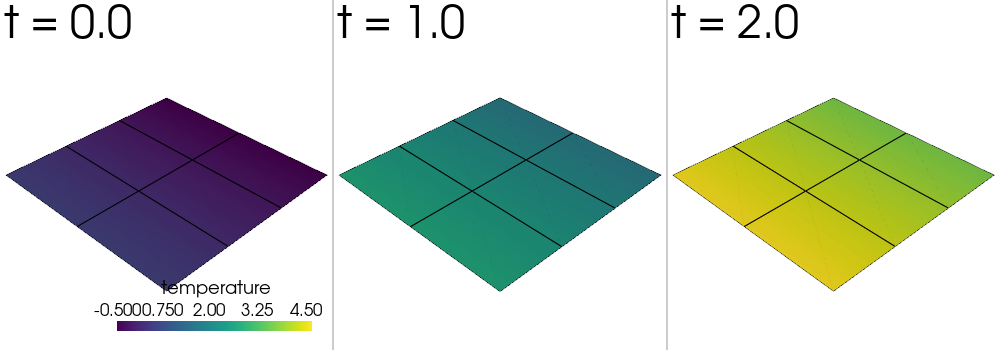

In [5]:
pl = pv.Plotter(shape=(1, 3), window_size=(1000, 350))
for index, time in enumerate([0.0, 1.0, 2.0]):
    pl.subplot(0, index)
    selected = series.at_time(time, method='linear')
    pl.add_mesh(selected, scalars='temperature', clim=(-0.5, 4.5), cmap='viridis', show_edges=True)
    pl.add_text(f't = {time}')
    pl.camera_position = 'iso'
pl.show(jupyter_backend='static')